# Validation: batched source integration vs CPU reference

Companion to `tests/test_jax_source.py`; every section **asserts** its
check. Compares the batched `fft` and `quad` amplitude extractions against
the per-mode CPU integrator, the committed golden data, physical
symmetries, and validates the built-in error estimates against true
errors.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import jax

from hblteuk.geo import MiniGeo
from hblteuk.collocode import generate_subdomain_list
from hblteuk.teuk import sigma_r
from hblteuk.jax import (spheroidal_eigs_batched, solve_homogeneous_batch,
                         orbit_samples, equatorial_swsh_values,
                         integrate_source_batch)

C = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]  # Okabe-Ito, fixed order

orbit = MiniGeo(0.9, 10.0, 0.2, 1.0)   # eccentric equatorial
a = orbit.a
kappa = np.sqrt(1 - a**2)
smin = sigma_r(orbit.radial_roots[0], kappa)
smax = sigma_r(orbit.radial_roots[1], kappa)
subs_up = generate_subdomain_list([0, smax], 150, "arcsinh7")
subs_in = generate_subdomain_list([1, smin], 150, "arcsinh7")
from hblteuk import collocode
from hblteuk.mode import TeukolskyPointParticleModeGenerator
import pathlib
golden = np.load(pathlib.Path("..") / "tests" / "golden" / "golden_v1.npz")

MODES = [(2, 2, n) for n in range(-3, 4)] + [(3, 1, 1), (10, 7, 0), (4, -3, 1)]
l_arr = np.array([c[0] for c in MODES])
m_arr = np.array([c[1] for c in MODES])
n_arr = np.array([c[2] for c in MODES])
omega = np.array([orbit.mode_frequency(m, 0, n) for _, m, n in MODES])
lam, coeffs, lmin = spheroidal_eigs_batched(-2, l_arr, m_arr, a * omega)
lam = np.asarray(lam)
hom = solve_homogeneous_batch(-2, kappa, lam, m_arr * a, omega, subs_up, subs_in)
samples = orbit_samples(orbit, nsamples=2**10)
S, dS, d2S = equatorial_swsh_values(-2, m_arr, lmin, coeffs, lam, a * omega)
res_fft = integrate_source_batch(samples, lam, m_arr, n_arr, omega,
                                 S, dS, d2S, hom, subs_up, subs_in, method="fft")
res_quad = integrate_source_batch(samples, lam, m_arr, n_arr, omega,
                                  S, dS, d2S, hom, subs_up, subs_in, method="quad")
amps = np.asarray(res_fft.amplitudes)
print("batch:", amps.shape)

batch: (10, 2)


## 1. FFT vs staggered quadrature

Same integrand $J$, two extraction routes — they must agree to machine
precision (the uniform sum *is* a DFT coefficient).

In [2]:
d = np.max(np.abs(np.asarray(res_fft.amplitudes) - np.asarray(res_quad.amplitudes))
           / np.abs(np.asarray(res_fft.amplitudes)))
print(f"max rel difference fft vs quad: {d:.2e}")
assert d < 1e-12

max rel difference fft vs quad: 5.72e-13


## 2. Against the per-mode CPU integrator

The CPU path solves its own (adaptive) radial solutions and integrates on
a half-period grid — an entirely independent computation of the same
amplitudes.

worst: 5.42e-09


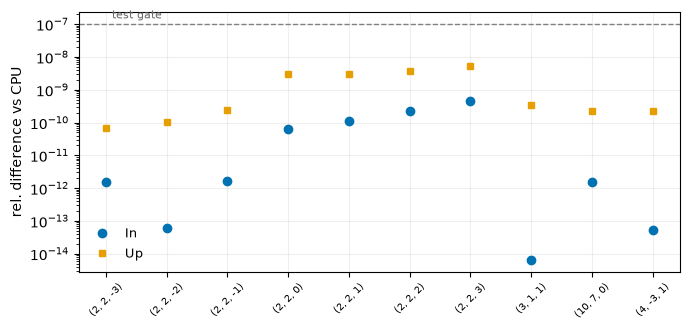

In [3]:
solver = collocode.CollocationODEMultiDomainFixedStepSolver(n=32)
gen = TeukolskyPointParticleModeGenerator(
    orbit, solver, {"subdomains": 150, "tol": 1e-13, "spacing": "arcsinh7"})
rel = []
for b, (l, m, n) in enumerate(MODES):
    mode = gen(-2, l, m, 0, n)
    cpu = np.array([mode.amplitudes["In"], mode.amplitudes["Up"]])
    rel.append(np.abs(amps[b] - cpu) / np.abs(cpu))
rel = np.array(rel)
assert rel.max() < 1e-7

fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(MODES))
ax.semilogy(x, np.maximum(rel[:, 0], 1e-17), "o", color=C[0], label="In")
ax.semilogy(x, np.maximum(rel[:, 1], 1e-17), "s", color=C[1], label="Up", ms=4)
ax.axhline(1e-7, ls="--", c="0.5", lw=1)
ax.text(0.1, 1.5e-7, "test gate", fontsize=8, color="0.4")
ax.set_xticks(x, [str(c) for c in MODES], rotation=45, fontsize=7)
ax.set_ylabel("rel. difference vs CPU")
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
print(f"worst: {rel.max():.2e}")

## 3. Golden data and conjugate symmetry

Golden: the committed regression amplitudes. Symmetry: equatorial orbits
satisfy $Z_{\ell,-m,-n} = (-1)^\ell \bar{Z}_{\ell m n}$ — computed here
from an independently solved $(-m, -n)$ batch.

In [4]:
for j, n in enumerate(golden["ecc_n"]):
    b = MODES.index((2, 2, int(n)))
    g = golden["ecc_amplitudes"][j]
    assert np.max(np.abs(amps[b] - g) / np.abs(g)) < 1e-7
print("golden regression: OK")

lam2, coeffs2, lmin2 = spheroidal_eigs_batched(-2, l_arr, -m_arr, -a * omega)
lam2 = np.asarray(lam2)
hom2 = solve_homogeneous_batch(-2, kappa, lam2, -m_arr * a, -omega,
                               subs_up, subs_in)
S2, dS2, d2S2 = equatorial_swsh_values(-2, -m_arr, lmin2,
                                       np.asarray(coeffs2), lam2, -a * omega)
amps2 = np.asarray(integrate_source_batch(
    samples, lam2, -m_arr, -n_arr, -omega, S2, dS2, d2S2,
    hom2, subs_up, subs_in).amplitudes)
sym = np.max(np.abs(amps2 - (-1.0)**l_arr[:, None] * np.conj(amps))
             / np.abs(amps))
assert sym < 1e-7
print(f"conjugate symmetry: max deviation {sym:.2e}")

golden regression: OK
conjugate symmetry: max deviation 1.01e-13


## 4. Do the error estimates mean anything?

A wide radial tower ($\ell = m = 2$, $|n| \le 12$) integrated on
progressively coarser grids; the built-in estimate is compared against the
*true* error (difference from the converged $2^{10}$-sample answer). The
estimator must never dangerously **under**estimate (points below the lower
dotted line); overestimating a nearly-converged mode is safe and does
happen.

140 resolved points; est/actual range [1.2e+00, 1.4e+12]; no dangerous underestimates


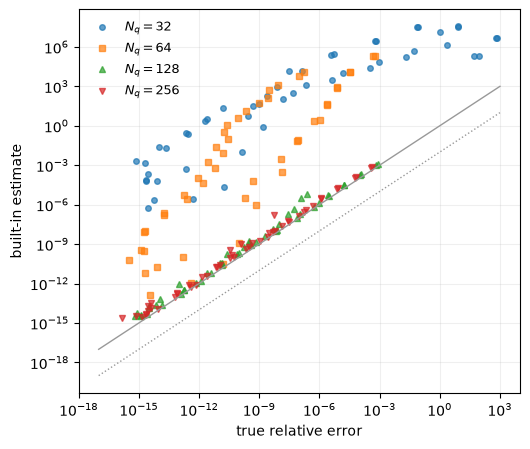

In [5]:
nw = np.arange(-12, 13)
lw_ = np.full_like(nw, 2); mw = np.full_like(nw, 2)
omw = np.array([orbit.mode_frequency(2, 0, int(n)) for n in nw])
lamw, coeffsw, lminw = spheroidal_eigs_batched(-2, lw_, mw, a * omw)
lamw = np.asarray(lamw)
homw = solve_homogeneous_batch(-2, kappa, lamw, mw * a, omw, subs_up, subs_in)
Sw, dSw, d2Sw = equatorial_swsh_values(-2, mw, lminw, np.asarray(coeffsw),
                                       lamw, a * omw)

def amps_at(ns):
    return integrate_source_batch(orbit_samples(orbit, nsamples=ns),
                                  lamw, mw, nw, omw, Sw, dSw, d2Sw,
                                  homw, subs_up, subs_in, method="fft")

ref = np.asarray(amps_at(2**10).amplitudes)
fig, ax = plt.subplots(figsize=(5.4, 4.6))
pts_est, pts_act = [], []
for ns, marker in [(2**5, "o"), (2**6, "s"), (2**7, "^"), (2**8, "v")]:
    r = amps_at(ns)
    est = np.asarray(r.errors).ravel()
    act = (np.abs(np.asarray(r.amplitudes) - ref) / np.abs(ref)).ravel()
    ax.loglog(np.maximum(act, 1e-17), np.maximum(est, 1e-17), marker,
              ms=4, alpha=0.7, label=rf"$N_q = {ns}$")
    pts_est.append(est); pts_act.append(act)
lo, hi = 1e-17, 1e3
ax.plot([lo, hi], [lo, hi], "-", c="0.6", lw=1)
ax.plot([lo, hi], [1e-2 * lo, 1e-2 * hi], ":", c="0.6", lw=1)
ax.set_xlabel("true relative error")
ax.set_ylabel("built-in estimate")
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()

est, act = np.concatenate(pts_est), np.concatenate(pts_act)
sel = act > 1e-12
ratio = est[sel] / act[sel]
assert np.all(ratio > 1e-2)
print(f"{sel.sum()} resolved points; est/actual range "
      f"[{ratio.min():.1e}, {ratio.max():.1e}]; no dangerous underestimates")

## Summary

1. FFT extraction ≡ staggered quadrature at machine precision
2. amplitudes match the independent per-mode CPU integrator (< 1e-7)
3. golden regression + conjugate symmetry hold
4. built-in FFT error estimates track true integration errors

`pytest tests/ -q` remains the canonical gate (37 tests).